# Partie 1 — Prétraitement des données
Étapes : valeurs aberrantes, valeurs manquantes, feature engineering, encodage,
séparation train / validation / test et normalisation **sans fuite de données**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

df = pd.read_csv('DatasetMorocco.csv')
features = df.select_dtypes('number').columns.drop('Fire')
df.shape

(299, 15)

## 1. Détection des valeurs aberrantes
Méthode IQR : une valeur est aberrante si elle est en dehors de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [2]:
Q1 = df[features].quantile(0.25)
Q3 = df[features].quantile(0.75)
IQR = Q3 - Q1

outliers = (df[features] < Q1 - 1.5 * IQR) | (df[features] > Q3 + 1.5 * IQR)
outliers.sum().sort_values(ascending=False)

precipitation_mm      53
NDWI                  41
wind_speed_mps        17
NBR                   15
NDMI                  14
NDVI                   5
pressure_hPa           0
humidity_percent       0
acq_time               0
temperature_C          0
latitude               0
wind_direction_deg     0
longitude              0
dtype: int64

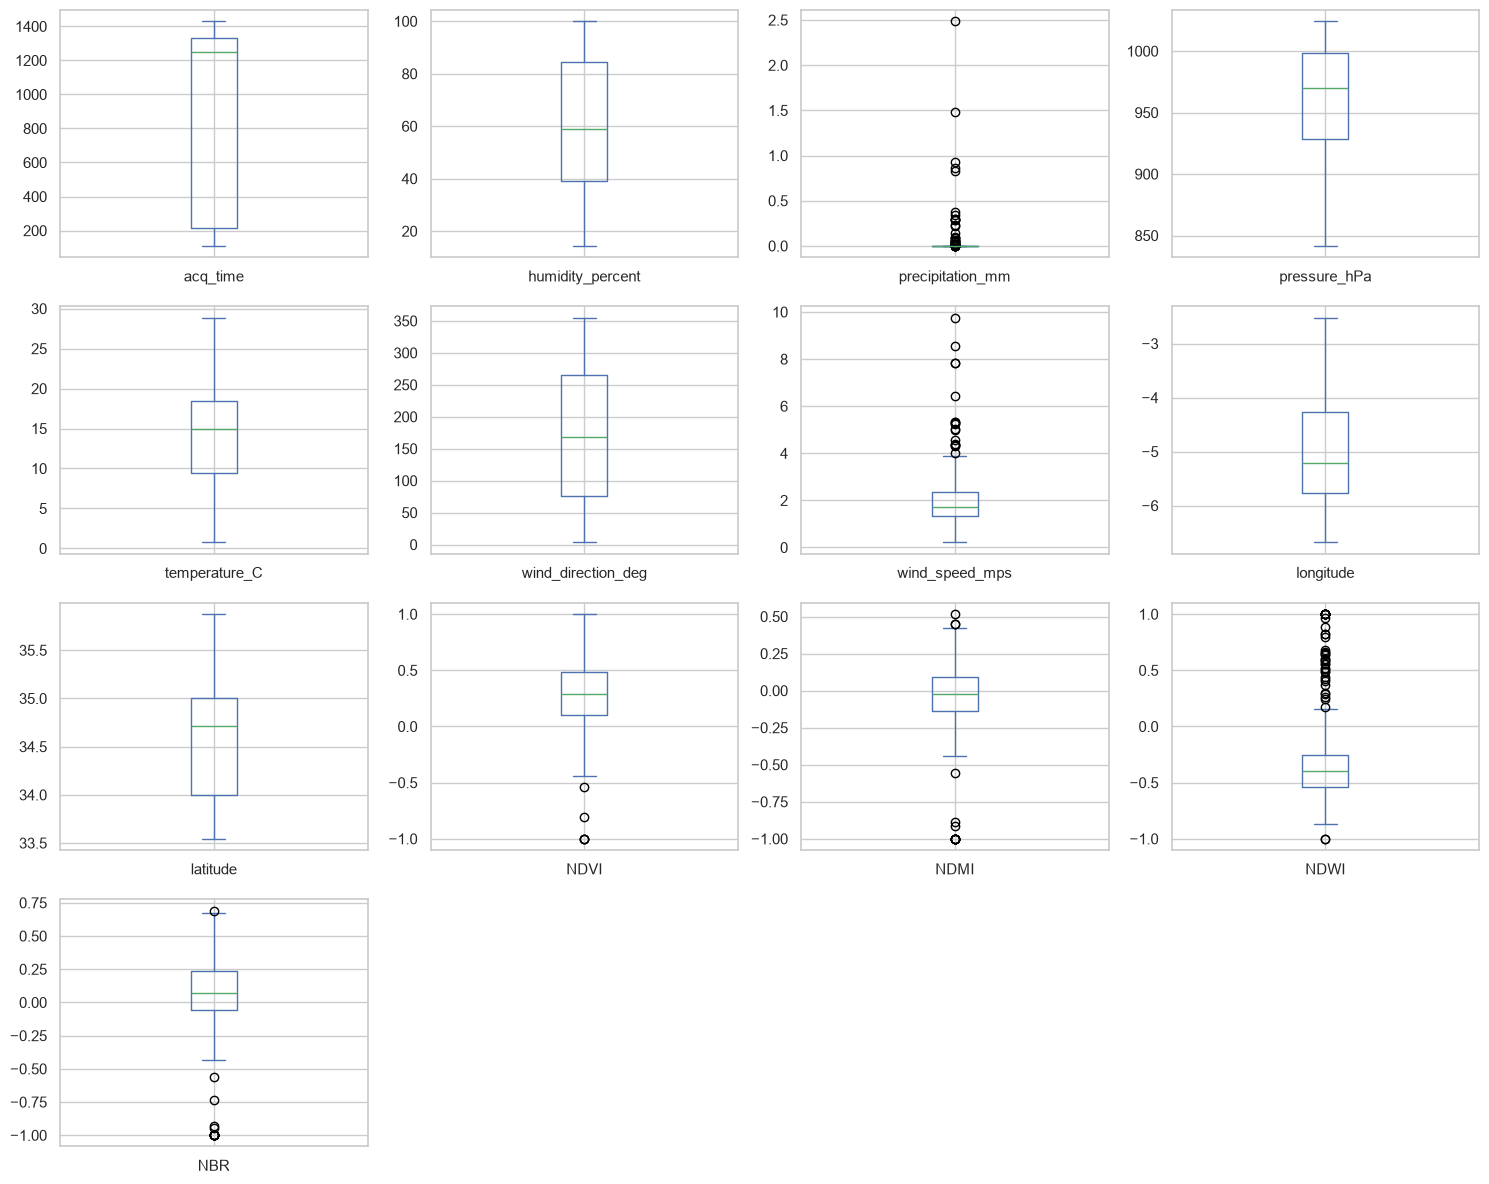

In [3]:
df[features].plot(kind='box', subplots=True, layout=(4, 4), figsize=(15, 12))
plt.tight_layout()
plt.show()

In [4]:
# Valeurs physiquement impossibles
print('Humidité > 100 % :', (df['humidity_percent'] > 100).sum())

# Indices spectraux égaux exactement à -1, 0 ou 1 (pixel nuageux / masqué = erreur de mesure)
indices = ['NDVI', 'NDMI', 'NDWI', 'NBR']
df[indices].isin([-1, 0, 1]).sum()

Humidité > 100 % : 1


NDVI    16
NDMI    15
NDWI    16
NBR     15
dtype: int64

**Traitement :**
- Humidité > 100 % → ramenée à 100.
- Indices égaux à -1, 0 ou 1 → remplacés par `NaN` (traités comme valeurs manquantes).
- Les autres valeurs extrêmes (pression basse en montagne, vent fort, pluie) sont de vraies mesures : on les **garde** (le dataset est petit).

In [5]:
df['humidity_percent'] = df['humidity_percent'].clip(upper=100)

for col in indices:
    df.loc[df[col].isin([-1, 0, 1]), col] = np.nan

## 2. Gestion des valeurs manquantes

In [6]:
df.isnull().sum()[lambda s: s > 0]

NDVI    16
NDMI    15
NDWI    16
NBR     15
dtype: int64

Peu de valeurs manquantes (environ 5 % par colonne) → on ne supprime rien.
On les remplacera par la **médiane**, calculée **uniquement sur le train** (voir section 6).

## 3. Feature engineering

In [7]:
date = pd.to_datetime(df['acq_date'])

# Date -> mois et saison
df['month'] = date.dt.month
df['season'] = np.where(df['month'] <= 2, 'hiver', 'printemps')

# acq_time (format HHMM, ex: 1340) -> heure, puis jour / nuit
df['hour'] = df['acq_time'] // 100
df['day_night'] = np.where(df['hour'].between(6, 18), 'jour', 'nuit')

# Direction du vent : variable circulaire (0° = 360°) -> sin / cos
angle = np.deg2rad(df['wind_direction_deg'])
df['wind_sin'] = np.sin(angle)
df['wind_cos'] = np.cos(angle)

# Indice de sécheresse : chaud + sec = risque de feu plus élevé
df['dryness'] = df['temperature_C'] * (100 - df['humidity_percent']) / 100

# Pluie presque toujours à 0 -> variable binaire "il pleut ?"
df['is_rain'] = (df['precipitation_mm'] > 0).astype(int)

# On supprime les colonnes remplacées
df = df.drop(columns=['acq_time', 'wind_direction_deg', 'precipitation_mm'])
df.head()

,Fire,acq_date,humidity_percent,pressure_hPa,temperature_C,wind_speed_mps,longitude,latitude,NDVI,NDMI,NDWI,NBR,month,season,hour,day_night,wind_sin,wind_cos,dryness,is_rain
0,0,2022-01-01,50.305471,943.095352,12.053644,1.211075,-3.435720,34.505224,0.118925,-0.202849,-0.271944,-0.130924,1,hiver,2,nuit,-0.880029,0.474921,5.990002,0
1,1,2022-01-01,71.519658,968.825352,7.565363,2.057297,-5.118192,33.945032,-0.333333,0.176471,0.795918,0.333333,1,hiver,2,nuit,0.190652,-0.981658,2.154641,0
2,1,2022-01-01,61.788530,1019.161758,19.497369,0.708083,-6.166009,34.877394,0.054914,-0.242592,-0.119941,-0.263492,1,hiver,13,jour,-0.743047,0.669240,7.450232,0
3,0,2022-01-02,39.120900,901.557969,8.234415,0.543159,-4.291256,34.755224,0.291355,-0.254314,-0.456077,-0.177430,1,hiver,2,nuit,0.992176,-0.124844,5.013038,0
4,0,2022-01-02,43.353296,973.095703,20.696130,1.462190,-6.062857,33.629880,0.258453,0.047219,-0.275808,0.149858,1,hiver,13,jour,-0.291413,0.956597,11.723676,0


## 4. Encodage des variables catégorielles
`season` et `day_night` n'ont pas d'ordre → **One-Hot Encoding** (une colonne 0/1 par modalité).
L'encodeur est mis dans le pipeline de la section 6 (appris sur le train).

In [8]:
cat_cols = ['season', 'day_night']
for col in cat_cols:
    print(df[col].value_counts(), '\n')

season
hiver        196
printemps    103
Name: count, dtype: int64 

day_night
jour    174
nuit    125
Name: count, dtype: int64 



## 5. Séparation train / validation / test (70 / 15 / 15)
Pour éviter la fuite de données :
- **stratification** : même proportion de feux dans chaque ensemble ;
- **groupes par date** : les observations d'un même jour ont la même météo, elles vont toutes dans le même ensemble ;
- le split est fait **avant** l'imputation et la normalisation.

In [9]:
from sklearn.model_selection import StratifiedGroupKFold

X = df.drop(columns=['Fire'])
y = df['Fire']

# 1) On sépare le test (~15 %)
split = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
train_val_idx, test_idx = next(split.split(X, y, groups=X['acq_date']))
X_train_val, X_test = X.iloc[train_val_idx], X.iloc[test_idx]
y_train_val, y_test = y.iloc[train_val_idx], y.iloc[test_idx]

# 2) On sépare la validation (~15 %) du reste
split = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
train_idx, val_idx = next(split.split(X_train_val, y_train_val, groups=X_train_val['acq_date']))
X_train, X_val = X_train_val.iloc[train_idx], X_train_val.iloc[val_idx]
y_train, y_val = y_train_val.iloc[train_idx], y_train_val.iloc[val_idx]

for nom, y_part in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    print(f'{nom:<10} : {len(y_part):3d} lignes | taux de feu = {y_part.mean():.2f}')

train      : 214 lignes | taux de feu = 0.61
validation :  42 lignes | taux de feu = 0.62
test       :  43 lignes | taux de feu = 0.58


In [10]:
# Vérification : aucune date en commun entre les ensembles
dates_train, dates_val, dates_test = set(X_train['acq_date']), set(X_val['acq_date']), set(X_test['acq_date'])
print('Dates communes :', len(dates_train & dates_val) + len(dates_train & dates_test) + len(dates_val & dates_test))

# La date ne sert plus (déjà transformée en month / season)
X_train, X_val, X_test = [x.drop(columns=['acq_date']) for x in (X_train, X_val, X_test)]

Dates communes : 0


## 6. Normalisation (pipeline de prétraitement)
- Variables numériques : imputation par la médiane + `StandardScaler` (moyenne 0, écart-type 1).
- Variables catégorielles : One-Hot Encoding.

Le pipeline est **appris (`fit`) sur le train uniquement**, puis **appliqué (`transform`)** sur validation et test.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = X_train.columns.drop(cat_cols).tolist()

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

X_train_p = preprocessor.fit_transform(X_train)   # fit sur le train seulement
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)

print('Train :', X_train_p.shape, '| Validation :', X_val_p.shape, '| Test :', X_test_p.shape)
print('Colonnes :', list(preprocessor.get_feature_names_out()))

Train : (214, 20) | Validation : (42, 20) | Test : (43, 20)
Colonnes : ['num__humidity_percent', 'num__pressure_hPa', 'num__temperature_C', 'num__wind_speed_mps', 'num__longitude', 'num__latitude', 'num__NDVI', 'num__NDMI', 'num__NDWI', 'num__NBR', 'num__month', 'num__hour', 'num__wind_sin', 'num__wind_cos', 'num__dryness', 'num__is_rain', 'cat__season_hiver', 'cat__season_printemps', 'cat__day_night_jour', 'cat__day_night_nuit']


In [12]:
# Vérification : sur le train, moyenne ≈ 0 et écart-type ≈ 1
X_train_df = pd.DataFrame(X_train_p, columns=preprocessor.get_feature_names_out())
X_train_df.describe().loc[['mean', 'std']].T.round(2)

,mean,std
num__humidity_percent,0.00,1.00
num__pressure_hPa,0.00,1.00
num__temperature_C,0.00,1.00
num__wind_speed_mps,0.00,1.00
num__longitude,0.00,1.00
num__latitude,-0.00,1.00
num__NDVI,-0.00,1.00
num__NDMI,-0.00,1.00
num__NDWI,-0.00,1.00
num__NBR,0.00,1.00


## 7. Sauvegarde pour la Partie 2

In [13]:
import joblib

joblib.dump({'X_train': X_train, 'X_val': X_val, 'X_test': X_test,
             'y_train': y_train, 'y_val': y_val, 'y_test': y_test,
             'preprocessor': preprocessor}, 'data_prepared.joblib')
print('Sauvegardé dans data_prepared.joblib')

Sauvegardé dans data_prepared.joblib


## Résumé
- **Valeurs aberrantes** : humidité ramenée à 100, indices spectraux à -1 / 0 / 1 → `NaN`, les autres valeurs extrêmes sont conservées.
- **Valeurs manquantes** : imputation par la médiane (apprise sur le train).
- **Feature engineering** : `month`, `season`, `hour`, `day_night`, `wind_sin/cos`, `dryness`, `is_rain`.
- **Encodage** : One-Hot pour `season` et `day_night`.
- **Séparation** : 70 / 15 / 15, stratifiée et groupée par date.
- **Normalisation** : `StandardScaler` appris sur le train seulement → pas de fuite de données.